# 疫情评论数据分析

## 准备工作

### 爬数据

In [1]:
%run CommentGet.py

填写验证码或扫描客户端二维码
主题：疫情
正在爬取第1页
正在爬取第2页
正在爬取第3页
正在爬取第4页
正在爬取第5页
正在爬取第6页
正在爬取第7页
正在爬取第8页
正在爬取第9页
正在爬取第10页
正在爬取第11页
正在爬取第12页
正在爬取第13页
正在爬取第14页
正在爬取第15页
正在爬取第16页
正在爬取第17页
正在爬取第18页
正在爬取第19页
正在爬取第20页
正在爬取第21页
正在爬取第22页
正在爬取第23页
正在爬取第24页
正在爬取第25页
正在爬取第26页
正在爬取第27页
正在爬取第28页
正在爬取第29页
正在爬取第30页
正在爬取第31页
正在爬取第32页
正在爬取第33页
正在爬取第34页
正在爬取第35页
正在爬取第36页
正在爬取第37页
正在爬取第38页
正在爬取第39页
正在爬取第40页
正在爬取第41页
正在爬取第42页
正在爬取第43页
正在爬取第44页
正在爬取第45页
正在爬取第46页
正在爬取第47页
正在爬取第48页
正在爬取第49页
正在爬取第50页
爬取完成
主题：新冠
正在爬取第1页
正在爬取第2页
正在爬取第3页
正在爬取第4页
正在爬取第5页
正在爬取第6页
正在爬取第7页
正在爬取第8页
正在爬取第9页
正在爬取第10页
正在爬取第11页
正在爬取第12页
正在爬取第13页
正在爬取第14页
正在爬取第15页
正在爬取第16页
正在爬取第17页
正在爬取第18页
正在爬取第19页
正在爬取第20页
正在爬取第21页
正在爬取第22页
正在爬取第23页
正在爬取第24页
正在爬取第25页
正在爬取第26页
正在爬取第27页
正在爬取第28页
正在爬取第29页
正在爬取第30页
正在爬取第31页
正在爬取第32页
正在爬取第33页
正在爬取第34页
正在爬取第35页
正在爬取第36页
正在爬取第37页
正在爬取第38页
正在爬取第39页
正在爬取第40页
正在爬取第41页
正在爬取第42页
正在爬取第43页
正在爬取第44页
正在爬取第45页
正在爬取第46页
正在爬取第47页
正在爬取第48页
正在爬取第49页
正在爬取第50页
爬取完成


### 资料导入

导入包

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import jieba
import re
import numpy as np
from PIL import Image
import geopandas as gpd

导入表格

In [3]:
data=pd.read_excel('Data/result.xlsx')
data.head()

,评论,省份
0,#向风而行承包你的2023机票# 2022年9月去长沙旅行的时候在飞机上拍的✈️每次坐飞机旅...,北京
1,//@无心简影:我唯一经历过的封控就是去年11月的那几周，不知道原博在憋屈什么？想篡改记忆？...,上海
2,新年第一天家里老人在感染第9天因为不停高烧住院了…\n\n血氧85，高烧38.7，被确诊是新...,河南
3,这次放开后有很大震荡但远没大到国外希望的那么大。国内疫情从清零、放开、震荡、平复的全过程数据...,江苏
4,【#妈妈用废纸箱给宝宝打造室内滑梯# ：用时一中午，孩子们很开心】12月31日，福建莆田。林...,黑龙江


读取停用词表

In [4]:
stop_words = open("Data/stop_words_full.txt",encoding="utf-8").read().split("\n")

读取省份信息

In [5]:
chinadata=gpd.read_file('Data/china.json')
chinadata.head()

,adcode,name,adchar,childrenNum,level,parent,subFeatureIndex,geometry
0,110000,北京,NaN,16.0,province,{'adcode': 100000},0.0,"MULTIPOLYGON (((117.34861 40.58114, 117.38988 ..."
1,120000,天津,NaN,16.0,province,{'adcode': 100000},1.0,"MULTIPOLYGON (((117.76560 39.40053, 117.84691 ..."
2,130000,河北,NaN,11.0,province,{'adcode': 100000},2.0,"MULTIPOLYGON (((117.46749 40.64974, 117.41267 ..."
3,140000,山西,NaN,11.0,province,{'adcode': 100000},3.0,"MULTIPOLYGON (((110.37926 34.60061, 110.42484 ..."
4,150000,内蒙古,NaN,12.0,province,{'adcode': 100000},4.0,"POLYGON ((97.17290 42.79526, 97.37123 42.45708..."


### 生成各省份图

全国轮廓图

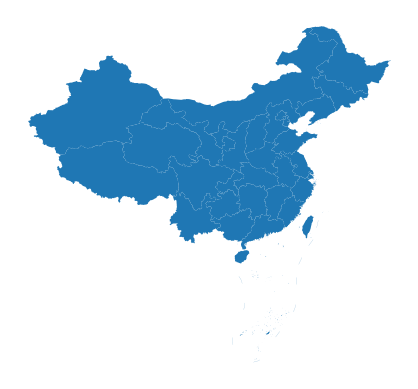

In [6]:
chinadata.plot(edgecolor=None)
plt.axis("off")
plt.savefig('Data/中国.png')

各省轮廓图

d:\Geography Program Files\ArcGIS Pro\Software\bin\Python\envs\bigdata\lib\site-packages\geopandas\plotting.py:675: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(figsize=figsize)


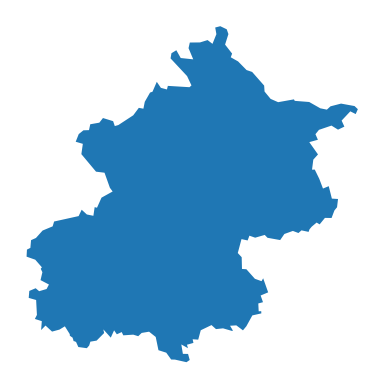

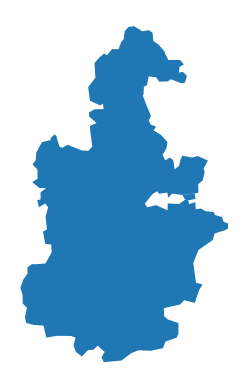

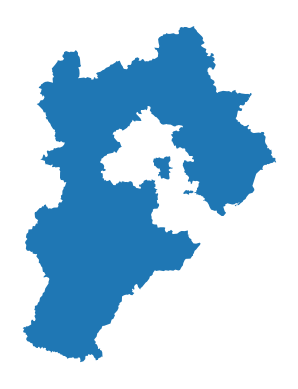

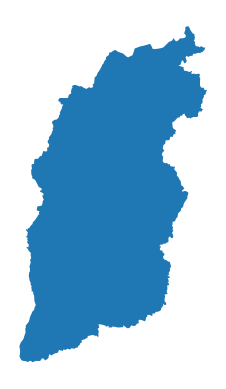

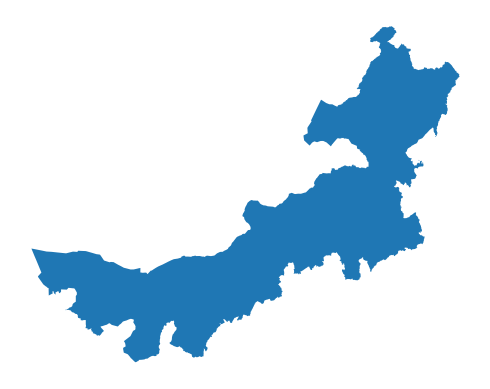

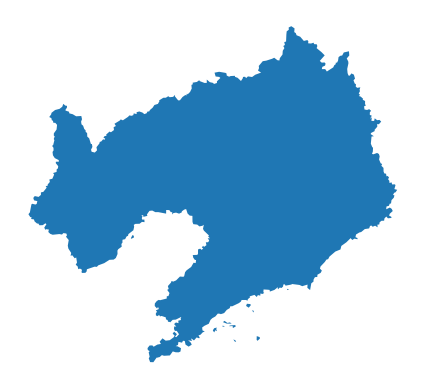

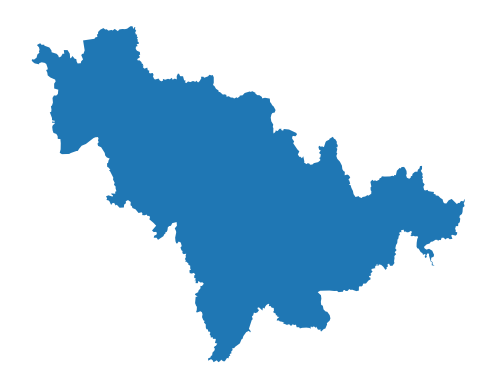

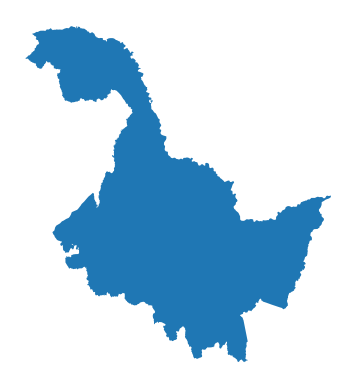

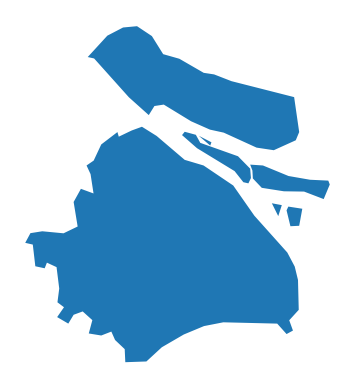

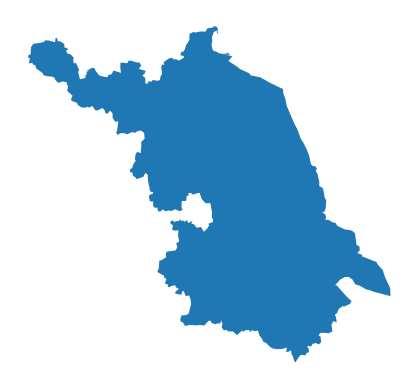

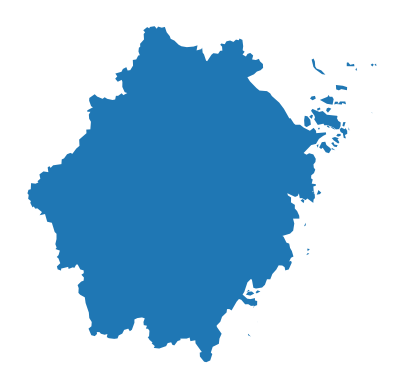

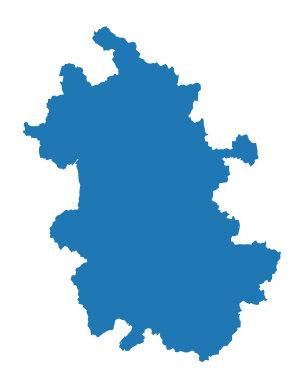

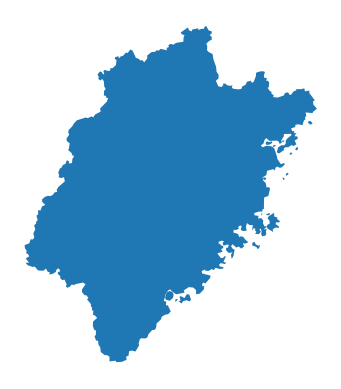

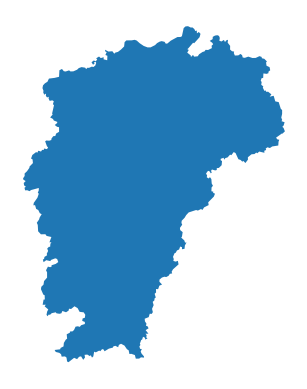

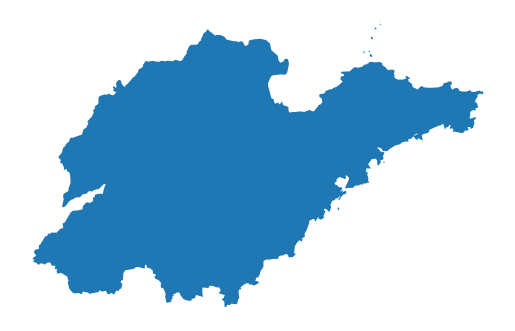

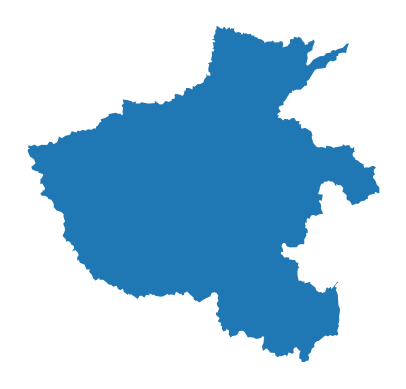

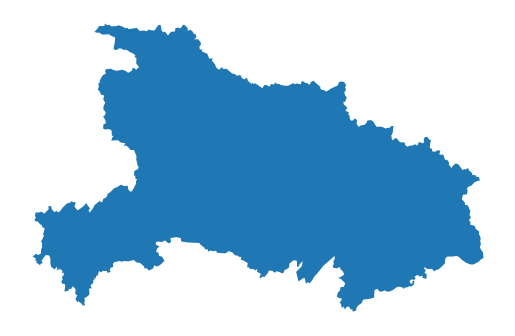

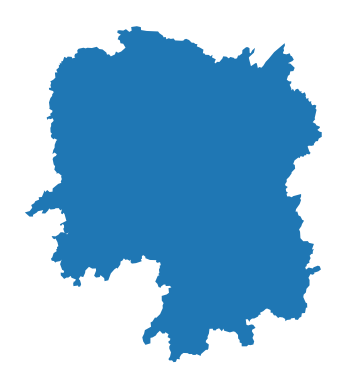

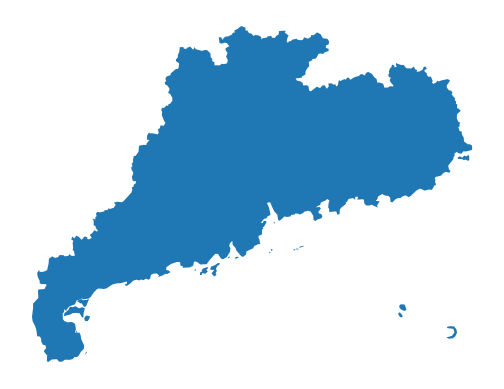

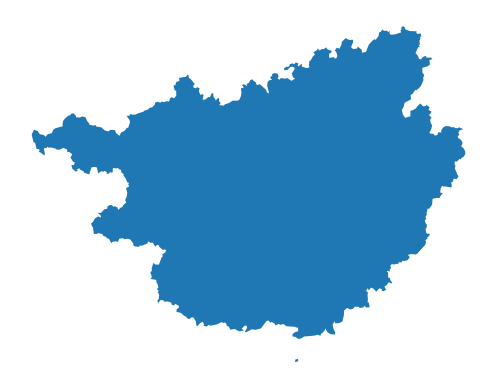

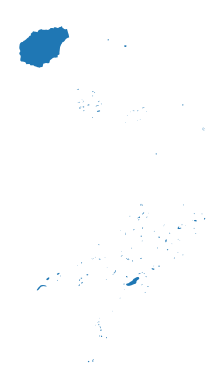

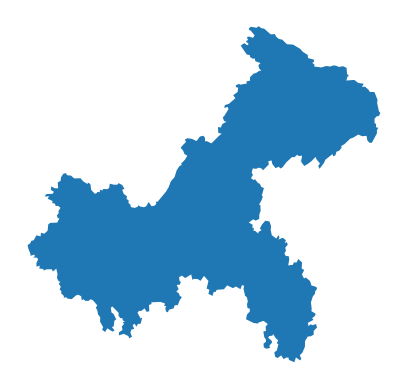

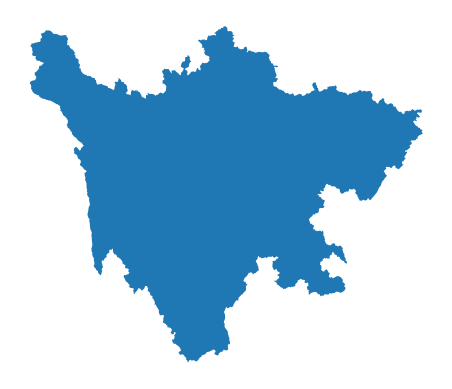

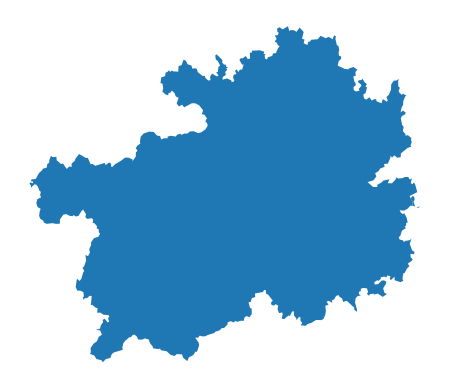

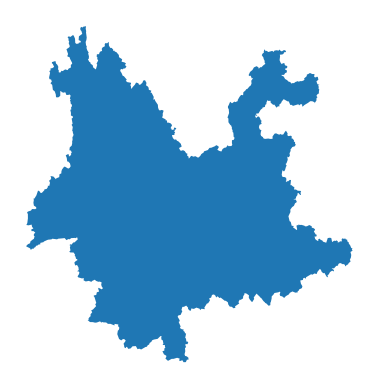

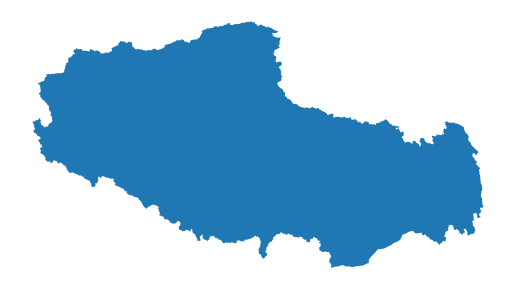

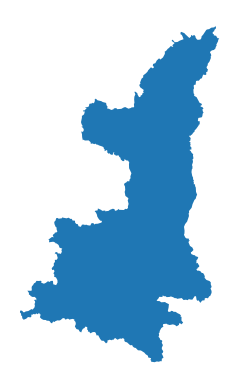

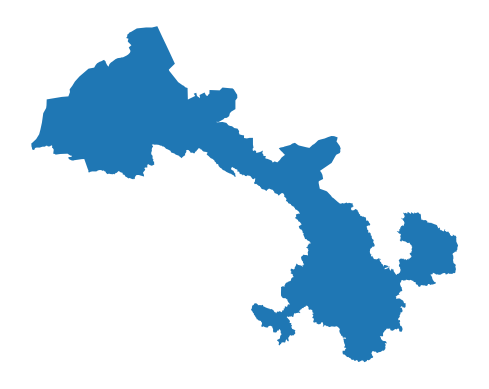

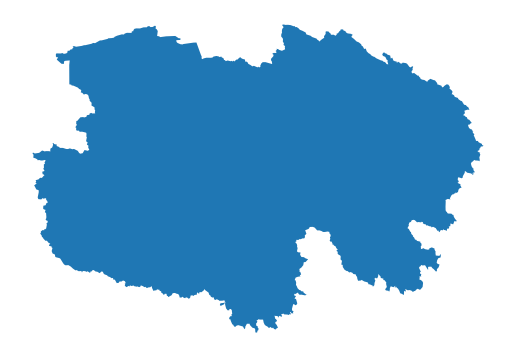

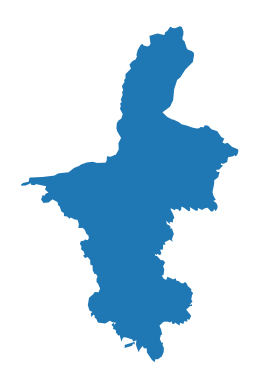

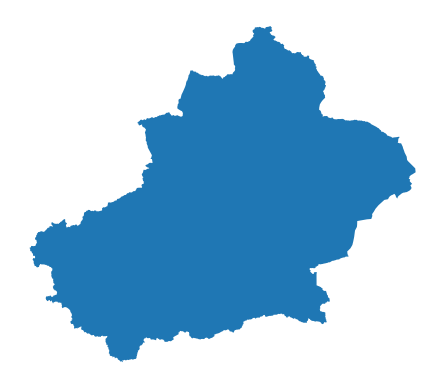

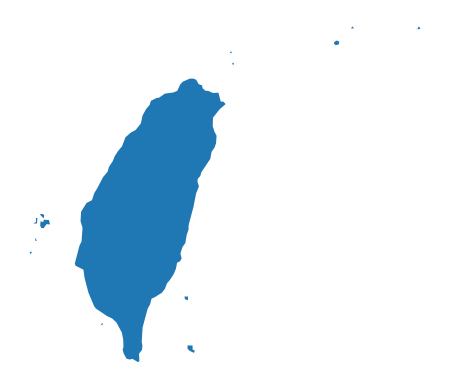

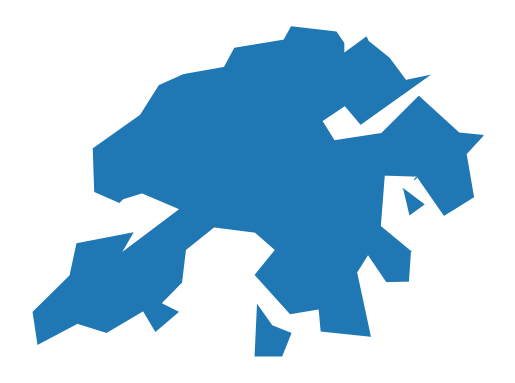

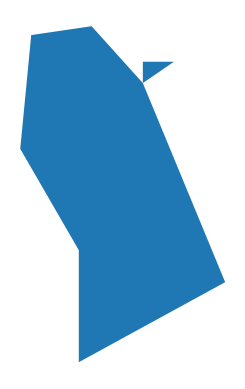

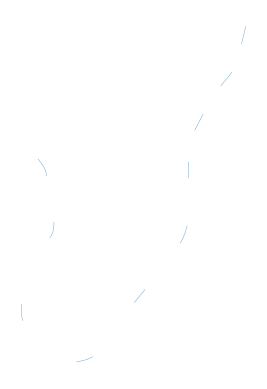

In [7]:
for index,row in chinadata.iterrows():
    # 遍历多边形并绘制每个Polygon
    pro=gpd.GeoDataFrame(data=[row],crs=chinadata.crs)
    pro.plot()
    plt.axis("off")
    plt.savefig('Data/%s.png'%row['name'])


## 数据分析

### 根据评论显示的不同ID生成不同省份的评论的词云图

过滤掉没有省份信息的行

In [8]:
df=data[data['省份']!='无地理位置信息']
df.head()

,评论,省份
0,#向风而行承包你的2023机票# 2022年9月去长沙旅行的时候在飞机上拍的✈️每次坐飞机旅...,北京
1,//@无心简影:我唯一经历过的封控就是去年11月的那几周，不知道原博在憋屈什么？想篡改记忆？...,上海
2,新年第一天家里老人在感染第9天因为不停高烧住院了…\n\n血氧85，高烧38.7，被确诊是新...,河南
3,这次放开后有很大震荡但远没大到国外希望的那么大。国内疫情从清零、放开、震荡、平复的全过程数据...,江苏
4,【#妈妈用废纸箱给宝宝打造室内滑梯# ：用时一中午，孩子们很开心】12月31日，福建莆田。林...,黑龙江


过滤掉不是中文英文字符的内容

In [9]:
# 定义一个函数，用于匹配中文、英文字符和标点符号
def filter_chars(text):
    pattern = re.compile('[^\u4e00-\u9fa5a-zA-Z,.;!?]') # 匹配非中英文标点符号和非中文英文字符
    return re.sub(pattern, '', text) # 替换为 ''

df['评论'] = df['评论'].apply(filter_chars)
df.head()

C:\Users\zhjw\AppData\Local\Temp\ipykernel_13476\3921551627.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['评论'] = df['评论'].apply(filter_chars)


,评论,省份
0,向风而行承包你的机票年月去长沙旅行的时候在飞机上拍的每次坐飞机旅行都喜欢选一个靠窗的座位领略...,北京
1,无心简影我唯一经历过的封控就是去年月的那几周不知道原博在憋屈什么想篡改记忆伊利达雷之怒别搁这...,上海
2,新年第一天家里老人在感染第天因为不停高烧住院了血氧高烧.被确诊是新冠肺炎看不懂片子没有发展成...,河南
3,这次放开后有很大震荡但远没大到国外希望的那么大国内疫情从清零放开震荡平复的全过程数据极其重要...,江苏
4,妈妈用废纸箱给宝宝打造室内滑梯用时一中午孩子们很开心月日福建莆田林女士发视频她和家人在家用剩...,黑龙江


按省份进行分类

In [10]:
df_province=df.groupby('省份')['评论'].agg(lambda x: ' '.join(x))
df_province.head()

省份
上海     无心简影我唯一经历过的封控就是去年月的那几周不知道原博在憋屈什么想篡改记忆伊利达雷之怒别搁这...
云南     噶玛巴千诺噶玛巴千诺噶玛巴千诺愿疫情早日退去愿世界和平愿国泰民安扎西德勒 名单公布个新冠病毒...
内蒙古    我的心愿有点简单又觉得复杂希望家人健康永远不生病不伤痛但这个也真的有点难我的守护不够强大到可...
北京     向风而行承包你的机票年月去长沙旅行的时候在飞机上拍的每次坐飞机旅行都喜欢选一个靠窗的座位领略...
台湾     元者善之长也亨者嘉之会也利者义之和也贞者事之干也元亨利贞元就是慎始这样事情才会顺利亨通利益要...
Name: 评论, dtype: object

根据省份轮廓图生成词云图

Building prefix dict from the default dictionary ...
Dumping model to file cache C:\Users\zhjw\AppData\Local\Temp\jieba.cache
Loading model cost 0.648 seconds.
Prefix dict has been built successfully.


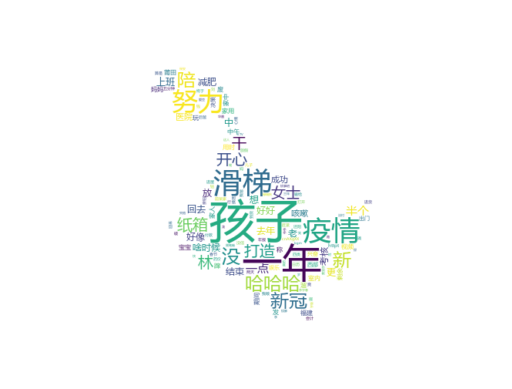

In [11]:
texth='' # 全国的
for province in df_province.keys():
    # 文字
    text=' '.join(jieba.cut(df_province[province]))
    texth+=' '+df_province[province]
    wordcloud = WordCloud(font_path='msyh.ttc',background_color='white',stopwords=stop_words,mask=np.array(Image.open('Data/%s.png'%province))).generate(text)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.savefig('词云图/%s.png'%province,format='png',dpi=1000)

全国的词云图

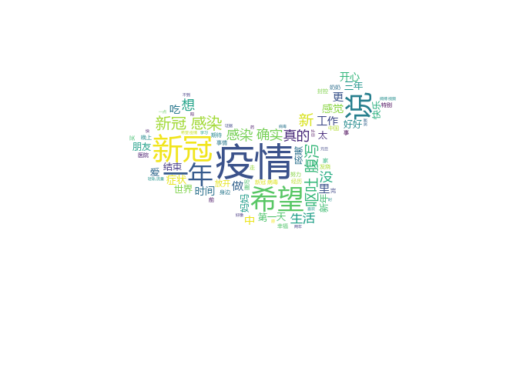

In [12]:
texth=' '.join(jieba.cut(texth))
wordcloud = WordCloud(font_path='msyh.ttc',background_color='white',stopwords=stop_words,mask=np.array(Image.open('Data/中国.png'))).generate(texth)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.savefig('词云图/中国.png',format='png',dpi=2000)

### 各省负面情绪相关词频统计

In [13]:
badword_list=['感染','病例','死亡','隔离','封锁','恐慌','疫区','疫情爆发','资源紧张','扩散','蔓延','防控','传播','传染','变异','影响','后果','封控','阳','挤兑','痛苦','恐惧','难过','艰难','去世','离去','离世','惨烈']

count_dict={}
for key in df_province.keys():
    count=0
    for words in badword_list:
        count+=df_province[key].count(words)
    count_dict[key]=count

count_df=pd.DataFrame.from_dict(count_dict, orient='index')
count_df.columns=['省份']
count_df.to_excel('负面词汇频数表.xlsx')